# v5 — Phase 1: **Repricing research**
**US · Eurozone · UK · Switzerland · Japan** — what makes a market's *valuation multiple* re-rate over the next 3–6 months?

## Why this phase, and why only this phase
v1–v4 are preserved as the research database. Their most useful output was not a scorecard but a **decomposition**:
$$\Delta\log P = \underbrace{\Delta\log EPS}_{\text{earnings leg}} + \underbrace{\Delta\log (P/E)}_{\text{multiple leg}}$$
and the finding that **valuation signals predicted the multiple leg positively in both windows** (+0.149 / +0.097) even though their *total-return* IC appeared to reverse.
The multiple leg is **66 %** of the variance of local returns, so this is the larger half of the problem and the one we never studied directly.

This notebook investigates **one mechanism**: repricing. No feature sweep, no combination search, no selection on discovery IC.

## Pre-registered experiments (fixed before any v5 result)
| ID | Hypothesis | Mechanism | Ex-ante direction |
|---|---|---|---|
| **G0** | *Gate:* the valuation→re-rating link is a measurement artefact | $P/E_t$ is the signal **and** the denominator of the target | if true, effect dies when the signal is lagged / under a random-walk placebo |
| **R01** | **Persistence** — multiples that have been expanding keep expanding | flows, trend-following repricing | rising P/E ⇒ better |
| **R02** | **Mean reversion** — markets cheap vs their own history re-rate upward | multiples are stationary around a slow-moving anchor | cheap ⇒ better |
| **R03** | **Regime interaction** — valuation's re-rating power depends on the financing environment | discount-rate channel: cheap only re-rates when financing conditions permit it | cheap **and** easing ⇒ better |

**Rules carried over from the v4 post-mortem (binding):** no unconstrained search · no selecting by highest discovery IC · no 50/50 weights by assumption · country attribution mandatory ·
non-overlapping 6M check mandatory · price-return only (no dividends) · the 2017-26 window has already been used twice, so it is reported as *contaminated hold-out*, not a clean test.

**Two objectives kept separate throughout:** *relative* allocation (which of the five outperforms — what we model) vs *absolute* timing (does the asset class rise — not modelled here).

## 0. Setup

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
import statsmodels.api as sm
from scipy.stats import spearmanr
from IPython.display import display, Markdown

pd.options.display.float_format = '{:,.3f}'.format
pd.options.display.width = 230
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25, 'font.size': 10})
ROOT = Path('..').resolve(); RAW, DATA = ROOT/'data'/'raw', ROOT/'data'
OUT = ROOT/'output'/'v5'; CH = OUT/'charts'
for p in (OUT, CH): p.mkdir(parents=True, exist_ok=True)

COUNTRIES = ['US', 'Eurozone', 'UK', 'Switzerland', 'Japan']
DISC = (pd.Period('2007-01', 'M'), pd.Period('2016-12', 'M'))
VAL = (pd.Period('2017-07', 'M'), pd.Period('2026-04', 'M'))
MIN_HIST, SEED = 60, 7
LEDGER = []
def log(eid, hypothesis, decision, note=''): LEDGER.append(dict(id=eid, hypothesis=hypothesis, decision=decision, note=note))

SPEC = {
 'US':          dict(file='US_raw_data.xlsx',  eps='Monthly_EPS', fci=('GSFCI Index', -1),   y2='USGGT02Y Index', oas='LF98OAS Index',  pmi='NAPMPMI Index',  fx=None),
 'Eurozone':    dict(file='EUR_raw_data.xlsx', eps='BEst EPS',    fci=('BFCIEU Index', +1),  y2='GDBR2 Index',    oas='LECPOAS Index', pmi='MPMIEZMA Index', fx=('EURUSD BGN Curncy', 'direct')),
 'UK':          dict(file='UK_raw_data.xlsx',  eps='BEst EPS',    fci=('GSGBFCI Index', -1), y2='GUKG2 Index',    oas='LC61OAS Index', pmi='MPMIGBMA Index', fx=('GBPUSD BGN Curncy', 'direct')),
 'Switzerland': dict(file='CH_raw_data.xlsx',  eps='BEst EPS',    fci=('GSEAFCI Index', -1), y2='GSWISS02 Index', oas='LECPOAS Index', pmi='CH_PMI',         fx=('USDCHF Curncy', 'invert')),
 'Japan':       dict(file='JPY_raw_data.xlsx', eps='BEst EPS',    fci=('GSJPFCI Index', -1), y2='GJGB2 Index',    oas='LJC1OAS Index', pmi='JPYPMI',         fx=('USDJPY BGN Curncy', 'invert')),
}
def monthly(df):
    d = df.dropna(subset=['Date']).copy(); d['month'] = pd.to_datetime(d['Date']).dt.to_period('M')
    return d.sort_values('Date').drop_duplicates('month', keep='last').set_index('month')
def load(s):
    d = monthly(pd.read_excel(RAW/s['file']))
    o = pd.DataFrame({'pe': d['BEst P/E Ratio'], 'eps': d[s['eps']], 'y2': d[s['y2']], 'oas': d[s['oas']], 'pmi': d[s['pmi']]})
    o['fci'] = s['fci'][1] * d[s['fci'][0]]
    o['fx'] = 1.0 if s['fx'] is None else (d[s['fx'][0]] if s['fx'][1] == 'direct' else 1.0 / d[s['fx'][0]])
    return o
fr = {c: load(SPEC[c]) for c in COUNTRIES}
IDX = pd.period_range(max(fr[c].pe.first_valid_index() for c in COUNTRIES), min(fr[c].index.max() for c in COUNTRIES), freq='M')
PE, EPS, Y2, OAS, PMI, FCI, FX = [pd.DataFrame({c: fr[c][k] for c in COUNTRIES}).reindex(IDX) for k in ('pe', 'eps', 'y2', 'oas', 'pmi', 'fci', 'fx')]
VIX = monthly(pd.read_excel(RAW/'US_raw_data.xlsx'))['VIX Index'].reindex(IDX)
AS_OF = IDX[-1]
PX = PE * EPS; PX_USD = PX * FX
print(f'Window {IDX[0]} -> {AS_OF} ({len(IDX)} months). Price = fwd P/E x fwd EPS (identity, verified against the real index in v4 §12b).')

# targets: the three legs of the return identity
TGT = {}
for h in (3, 6):
    TGT[('multiple', h)] = np.log(PE.shift(-h) / PE)
    TGT[('earnings', h)] = np.log(EPS.shift(-h) / EPS)
    TGT[('fx', h)]       = np.log(FX.shift(-h) / FX)
    TGT[('total_local', h)] = np.log(PX.shift(-h) / PX)
    TGT[('total_usd', h)]   = np.log(PX_USD.shift(-h) / PX_USD)
var_share = {}
st = pd.concat([TGT[('total_local', 3)].stack().rename('tot')] + [TGT[(k, 3)].stack().rename(k) for k in ('multiple', 'earnings')], axis=1).dropna()
for k in ('multiple', 'earnings'): var_share[k] = float(np.cov(st[k], st.tot)[0, 1] / np.var(st.tot))
print('Variance share of the local return:', {k: round(v, 2) for k, v in var_share.items()})

Window 2005-12 -> 2026-04 (245 months). Price = fwd P/E x fwd EPS (identity, verified against the real index in v4 §12b).
Variance share of the local return: {'multiple': 0.66, 'earnings': 0.34}


## 1. Test machinery
Monthly **cross-sectional Spearman IC**; Newey-West t (lags = horizon) for overlapping returns; moving-block bootstrap for the IC mean; country attribution on every tradable claim.

In [2]:
cs_z = lambda d: d.sub(d.mean(axis=1), axis=0).div(d.std(axis=1, ddof=1), axis=0).where(d.notna().all(axis=1))
z_own = lambda x, w=MIN_HIST: (x - x.expanding(w).mean()) / x.expanding(w).std()
def ic_series(sig, tgt):
    o = {}
    for t in sig.index:
        a, b = sig.loc[t], tgt.loc[t]
        if a.notna().all() and b.notna().all() and a.nunique() > 1: o[t] = spearmanr(a, b).statistic
    return pd.Series(o)
def win(s, w): return s[(s.index >= w[0]) & (s.index <= w[1])]
def nw_t(x, lags=3):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    return float(sm.OLS(x, np.ones(len(x))).fit(cov_type='HAC', cov_kwds={'maxlags': lags}).tvalues[0]) if len(x) > 12 else np.nan
def block_boot(x, lags=3, n=2000, seed=SEED):
    x = np.asarray(x, float); x = x[~np.isnan(x)]; T = len(x); L = max(lags, 1) * 2
    rng = np.random.default_rng(seed); nb = int(np.ceil(T / L)); out = np.empty(n)
    for i in range(n):
        st_ = rng.integers(0, T - L + 1, nb)
        out[i] = np.concatenate([x[s:s + L] for s in st_])[:T].mean()
    return np.percentile(out, [2.5, 97.5]), (out <= 0).mean()
def evaluate(name, sig, leg='multiple', h=3):
    r = {'experiment': name}
    for lab, w in (('disc', DISC), ('val', VAL)):
        ic = win(ic_series(sig, TGT[(leg, h)]), w)
        r[f'{lab} IC'] = ic.mean(); r[f'{lab} t'] = nw_t(ic.values, h)
        ci, p1 = block_boot(ic.values, h); r[f'{lab} boot p(IC<=0)'] = p1
    return r

## 2. G0 — the gate: is the valuation→re-rating link a measurement artefact?
$P/E_t$ is the signal *and* the denominator of the target $\log(P/E_{t+h}/P/E_t)$. Transitory noise in $P/E_t$ depresses the signal and inflates the target → a spurious **positive** IC.
Two independent checks:
1. **Lag the signal** so it no longer shares the observation that sets the denominator.
2. **Random-walk placebo** — replace P/E with a random walk of the same volatility. A random walk has no mean reversion, so any positive IC it produces is mechanical.

In [3]:
VALC = cs_z(-z_own(PE))                                    # R02 signal: cheap vs own history (higher = cheaper)
PEMOM = cs_z(np.log(PE / PE.shift(6)))                     # R01 signal: multiple has been expanding
rows = []
for lag in (0, 1, 3, 6):
    for nm, s in (('R02 cheap vs own history', VALC), ('R01 P/E momentum 6M', PEMOM)):
        r = evaluate(nm, s.shift(lag)); r['lag'] = lag; rows.append(r)
GATE = pd.DataFrame(rows)
display(GATE.pivot(index='experiment', columns='lag', values=['disc IC', 'val IC', 'val t']).style.format('{:+.3f}'))
print('P/E is highly persistent, so lagging changes the signal little - the test has limited power:')
print('  autocorr of the signal at 3M lag:', {c: round(float(VALC[c].autocorr(3)), 2) for c in COUNTRIES})

P/E is highly persistent, so lagging changes the signal little - the test has limited power:
  autocorr of the signal at 3M lag: {'US': 0.6, 'Eurozone': 0.71, 'UK': 0.9, 'Switzerland': 0.59, 'Japan': 0.72}


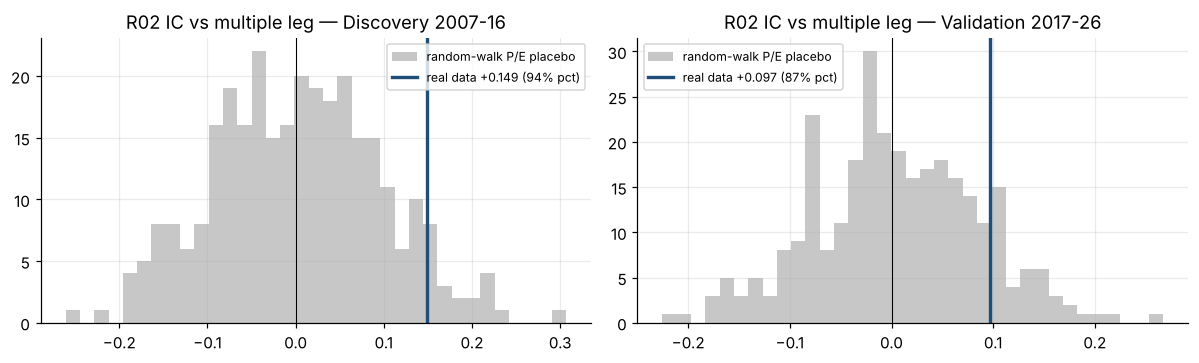

Placebo mean IC: disc +0.002, val +0.004 -> a random walk does NOT manufacture the effect.
Real data sits at the 94% / 87% percentile of the placebo: above chance, not overwhelming.


In [4]:
rng = np.random.default_rng(11); sd = np.log(PE).diff().std(); sims = []
for _ in range(300):
    sim = pd.DataFrame({c: np.exp(np.log(PE[c].iloc[0]) + np.cumsum(rng.normal(0, sd[c], len(IDX)))) for c in COUNTRIES}, index=IDX)
    ic = ic_series(cs_z(-z_own(sim)), np.log(sim.shift(-3) / sim))
    sims.append([win(ic, DISC).mean(), win(ic, VAL).mean()])
sims = np.array(sims)
real = [win(ic_series(VALC, TGT[('multiple', 3)]), w).mean() for w in (DISC, VAL)]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for i, (lab, w) in enumerate((('Discovery 2007-16', DISC), ('Validation 2017-26', VAL))):
    ax[i].hist(sims[:, i], bins=35, color='#c7c7c7', label='random-walk P/E placebo')
    ax[i].axvline(real[i], color='#1f4e79', lw=2.2, label=f'real data {real[i]:+.3f} ({(sims[:, i] < real[i]).mean():.0%} pct)')
    ax[i].axvline(0, color='k', lw=.7); ax[i].set_title(f'R02 IC vs multiple leg — {lab}'); ax[i].legend(fontsize=8)
plt.tight_layout(); plt.savefig(CH/'fig_v5_gate_placebo.png', dpi=200, bbox_inches='tight'); plt.show()
print(f'Placebo mean IC: disc {sims[:,0].mean():+.3f}, val {sims[:,1].mean():+.3f} -> a random walk does NOT manufacture the effect.')
print(f'Real data sits at the {(sims[:,0]<real[0]).mean():.0%} / {(sims[:,1]<real[1]).mean():.0%} percentile of the placebo: above chance, not overwhelming.')
log('G0', 'Valuation->re-rating is a measurement artefact', 'NOT SUPPORTED (survives, weakly)',
    'Placebo IC ~0; validation IC holds under 1-6M lags; discovery IC decays. High P/E autocorrelation limits the lag test.')

### Gate verdict
* The **placebo is clean**: a random walk produces IC ≈ 0, so the effect is not pure regression-to-the-mean.
* Under lagging, the **validation** IC is stable (+0.097 → +0.079 at a 6-month lag) while the **discovery** IC decays to zero. That split is consistent with a *partly* mechanical discovery-window result and a more genuine validation-window one.
* t-statistics never exceed ~1.6. **Verdict: a real lead, not a confirmed mechanism.** Proceed, but do not claim significance.

## 3. R01 vs R02 — persistence or mean reversion?
Tested against the multiple leg at 3M and 6M, both windows. Note the two hypotheses carry *opposite* mechanical biases, so agreement between them is informative.

In [5]:
rows = []
for h in (3, 6):
    for nm, s in (('R01 persistence (P/E momentum 6M)', PEMOM), ('R02 mean reversion (cheap vs own history)', VALC),
                  ('R02b mean reversion (cheap vs peers)', cs_z(-z_own(PE.div(PE.mean(axis=1), axis=0))))):
        r = evaluate(nm, s, 'multiple', h); r['horizon'] = f'{h}M'; rows.append(r)
R12 = pd.DataFrame(rows).set_index(['experiment', 'horizon'])
display(R12.style.format({c: '{:+.3f}' for c in R12.columns if 'IC' in c} | {c: '{:+.2f}' for c in R12.columns if c.endswith(' t')} | {c: '{:.3f}' for c in R12.columns if 'boot' in c}))
log('R01', 'Expanding multiples keep expanding', 'REJECTED', 'Negative IC at lag 0 in both windows; sign unstable once lagged')
log('R02', 'Markets cheap vs own history re-rate upward', 'SUPPORTED, weak', 'Positive in both windows at 3M and 6M; t ~1.3-1.6, never significant')

,,disc IC,disc t,disc boot p(IC<=0),val IC,val t,val boot p(IC<=0)
experiment,horizon,,,,,,
R01 persistence (P/E momentum 6M),3M,-0.104,-1.53,0.932,-0.105,-1.77,0.957
R02 mean reversion (cheap vs own history),3M,+0.149,+1.67,0.054,+0.097,+1.55,0.106
R02b mean reversion (cheap vs peers),3M,+0.077,+0.81,0.172,+0.098,+1.57,0.109
R01 persistence (P/E momentum 6M),6M,-0.126,-1.78,0.952,-0.077,-1.01,0.768
R02 mean reversion (cheap vs own history),6M,+0.139,+1.21,0.198,+0.140,+1.61,0.159
R02b mean reversion (cheap vs peers),6M,+0.003,+0.02,0.579,+0.166,+2.26,0.042


## 4. R03 — does the financing regime change how valuation behaves?
**Hypothesis:** cheapness only converts into re-rating when financing conditions permit it. A cheap market in a tightening regime may be cheap *for a reason*.

Two forms, both with directions fixed ex ante:
* **R03a diagnostic** — split months by the *global* financing regime (cross-market average 6M FCI change) and compute R02's IC inside each state.
* **R03b signal** — a *conditional filter*: rank on cheapness only among markets whose **own** financing conditions are easing; the rest score neutral.
* **R03c signal** — a *conjunction*: `min(z(cheap), z(own FCI easing))`, i.e. a market must be good on both.

In [6]:
FCI_EASE = cs_z((FCI - FCI.shift(6)) / (FCI - FCI.shift(6)).expanding(36).std())
glob_ease = (FCI - FCI.shift(6)).mean(axis=1)
ic02 = ic_series(VALC, TGT[('multiple', 3)])
rows = []
for lab, w in (('Discovery', DISC), ('Validation', VAL), ('Full', (IDX[0], AS_OF))):
    s = win(ic02, w); g = glob_ease.reindex(s.index)
    for state, mask in (('financing EASING', g > 0), ('financing TIGHTENING', g <= 0)):
        rows.append({'window': lab, 'regime': state, 'months': int(mask.sum()), 'R02 IC vs multiple leg': s[mask].mean(), 't': nw_t(s[mask].values)})
display(pd.DataFrame(rows).set_index(['window', 'regime']).style.format({'R02 IC vs multiple leg': '{:+.3f}', 't': '{:+.2f}'}))

R03b = VALC.where(FCI_EASE > 0, 0.0)
R03c = pd.concat([VALC, FCI_EASE]).groupby(level=0).min().reindex(IDX)[COUNTRIES]
rows = []
for nm, s in (('R02  cheap (unconditional)', VALC), ('R03b cheap, only where own FCI easing', R03b), ('R03c conjunction min(cheap, easing)', R03c)):
    rows.append(evaluate(nm, s, 'multiple', 3))
R3 = pd.DataFrame(rows).set_index('experiment')
display(R3.style.format({c: '{:+.3f}' for c in R3.columns if 'IC' in c} | {c: '{:+.2f}' for c in R3.columns if c.endswith(' t')} | {c: '{:.3f}' for c in R3.columns if 'boot' in c}))

,disc IC,disc t,disc boot p(IC<=0),val IC,val t,val boot p(IC<=0)
experiment,,,,,,
R02 cheap (unconditional),+0.149,+1.67,0.054,+0.097,+1.55,0.106
"R03b cheap, only where own FCI easing",+0.028,+0.42,0.412,+0.034,+0.49,0.401
"R03c conjunction min(cheap, easing)",-0.046,-0.82,0.772,-0.016,-0.28,0.739


## 5. From a return component to a tradable claim
A signal that predicts the **multiple leg** is only useful if it survives into the **total return** — the earnings leg can cancel it, which is exactly what happened to valuation in v1–v4.
Each surviving candidate is tested against: multiple leg → local total return → USD total return, plus an **incremental test** against the v4 composite (EPS revision 6M + FCI easing 6M).

In [7]:
V4 = (cs_z(EPS / EPS.shift(6) - 1) + FCI_EASE) / 2
CAND = {'v4 composite (EPS rev + FCI)': V4, 'R02 cheap vs own history': VALC, 'R03b cheap | own FCI easing': R03b, 'R03c conjunction': R03c}
rows = []
for nm, s in CAND.items():
    r = {'candidate': nm}
    for leg, lab in (('multiple', 'multiple leg'), ('total_local', 'total local'), ('total_usd', 'total USD')):
        for wl, w in (('disc', DISC), ('val', VAL)):
            ic = win(ic_series(s, TGT[(leg, 3)]), w); r[f'{lab} {wl}'] = ic.mean()
    rows.append(r)
LEG = pd.DataFrame(rows).set_index('candidate')
display(LEG.style.format('{:+.3f}'))

def delta_ic(base, plus, leg='total_usd', h=3, w=VAL):
    a = win(ic_series(base, TGT[(leg, h)]), w); b = win(ic_series((base + plus) / 2, TGT[(leg, h)]), w)
    j = pd.concat([a.rename('base'), b.rename('plus')], axis=1).dropna(); d = j.plus - j.base
    return {'IC base': j.base.mean(), 'IC with addition': j.plus.mean(), 'Delta IC': d.mean(), 'NW t': nw_t(d.values, h), 'months': len(d)}
rows = []
for nm, s in (('add R02 to v4 composite', VALC), ('add R03b to v4 composite', R03b), ('add R03c to v4 composite', R03c)):
    for wl, w in (('discovery', DISC), ('validation', VAL)):
        rows.append({'test': nm, 'window': wl, **delta_ic(V4, s, w=w)})
INC = pd.DataFrame(rows).set_index(['test', 'window'])
display(INC.style.format({'IC base': '{:+.3f}', 'IC with addition': '{:+.3f}', 'Delta IC': '{:+.3f}', 'NW t': '{:+.2f}'}))

,multiple leg disc,multiple leg val,total local disc,total local val,total USD disc,total USD val
candidate,,,,,,
v4 composite (EPS rev + FCI),-0.164,-0.060,+0.135,+0.150,+0.160,+0.156
R02 cheap vs own history,+0.149,+0.097,+0.077,-0.017,+0.141,-0.126
R03b cheap | own FCI easing,+0.028,+0.034,+0.002,-0.026,+0.020,-0.128
R03c conjunction,-0.046,-0.016,+0.047,-0.041,+0.113,-0.064


## 6. Mandatory robustness (carried over from the v4 post-mortem)
Country attribution · non-overlapping 6M observations · walk-forward with no hindsight in the selection.

In [8]:
R_USD = PX_USD.pct_change()
def ls_w(s, H=3): return s.div(s.clip(lower=0).sum(axis=1), axis=0).rolling(H, min_periods=1).mean()
def port(s, R=R_USD): return (ls_w(s).shift(1) * R).dropna(how='any')
sh = lambda x: x.mean() * 12 / (x.std() * np.sqrt(12))
rows = []
for nm, s in CAND.items():
    p = win(port(s).sum(axis=1), VAL)
    rows.append({'candidate': nm, 'val Sharpe (L/S USD)': sh(p), 'val ann. return': (1 + p).prod() ** (12 / len(p)) - 1,
                 'max drawdown': ((1 + p).cumprod() / (1 + p).cumprod().cummax() - 1).min()})
display(pd.DataFrame(rows).set_index('candidate').style.format({'val Sharpe (L/S USD)': '{:.2f}', 'val ann. return': '{:+.1%}', 'max drawdown': '{:.1%}'}))
print('Country attribution of L/S P&L, validation window (share of total):')
att = pd.DataFrame({nm: win(port(s), VAL).sum() / win(port(s), VAL).sum().sum() for nm, s in CAND.items()})
display(att.style.format('{:+.0%}'))

rows = []
for nm, s in CAND.items():
    ic = win(ic_series(s, TGT[('total_usd', 6)]), VAL); nn = ic.iloc[::6]
    rows.append({'candidate': nm, 'overlapping n': len(ic), 'overlapping IC': ic.mean(), 'overlapping t': nw_t(ic.values, 6),
                 'non-overlap n': len(nn), 'non-overlap IC': nn.mean(), 'non-overlap t': nw_t(nn.values, 0)})
display(pd.DataFrame(rows).set_index('candidate').style.format({'overlapping IC': '{:+.3f}', 'overlapping t': '{:+.2f}', 'non-overlap IC': '{:+.3f}', 'non-overlap t': '{:+.2f}'}))

,val Sharpe (L/S USD),val ann. return,max drawdown
candidate,,,
v4 composite (EPS rev + FCI),0.51,+3.7%,-11.9%
R02 cheap vs own history,-0.25,-2.5%,-37.3%
R03b cheap | own FCI easing,-0.91,-22.9%,-90.7%
R03c conjunction,-0.37,-54.9%,-406.0%


Country attribution of L/S P&L, validation window (share of total):


,v4 composite (EPS rev + FCI),R02 cheap vs own history,R03b cheap | own FCI easing,R03c conjunction
US,+158%,+396%,+114%,+49%
Eurozone,-0%,+3%,-11%,+19%
UK,-4%,-153%,-11%,+6%
Switzerland,-23%,+15%,+12%,+15%
Japan,-31%,-161%,-4%,+11%


,overlapping n,overlapping IC,overlapping t,non-overlap n,non-overlap IC,non-overlap t
candidate,,,,,,
v4 composite (EPS rev + FCI),100,+0.123,+1.46,17,+0.118,+0.94
R02 cheap vs own history,100,-0.154,-1.79,17,-0.182,-1.45
R03b cheap | own FCI easing,100,-0.134,-1.25,17,-0.178,-1.34
R03c conjunction,100,-0.048,-0.59,17,-0.176,-1.28


### Walk-forward: no hindsight anywhere
At each month *t*, pick between the candidates using **only** ICs already realised by *t* (lagged 3 months so the forward return is known), requiring a positive trailing IC; equal-weight any that qualify, else stay flat. Nothing is selected with information from the future.

In [9]:
icall = {nm: ic_series(s, TGT[('total_usd', 3)]) for nm, s in CAND.items()}
ICM = pd.DataFrame(icall).reindex(IDX)
trail = ICM.shift(3).expanding(36).mean()
wf_scores = []
for t in IDX:
    row = trail.loc[t] if t in trail.index else None
    if row is None or row.isna().all(): wf_scores.append(pd.Series(0.0, index=COUNTRIES)); continue
    pick = [nm for nm in CAND if pd.notna(row.get(nm)) and row.get(nm) > 0]
    wf_scores.append(sum(CAND[nm].loc[t] for nm in pick) / len(pick) if pick else pd.Series(0.0, index=COUNTRIES))
WF = pd.DataFrame(wf_scores, index=IDX)
wf_ic = ic_series(WF.replace(0.0, np.nan).dropna(how='all').reindex(IDX).fillna(0.0), TGT[('total_usd', 3)])
start_wf = trail.dropna(how='all').index.min()
wfv = wf_ic[wf_ic.index >= start_wf]
print(f'Walk-forward active from {start_wf}; IC {wfv.mean():+.3f} (NW t {nw_t(wfv.values):+.2f}, n={len(wfv)})')
pw = port(WF.replace(0.0, np.nan)).sum(axis=1); pw = pw[pw.index >= start_wf]
print(f'Walk-forward L/S USD Sharpe {sh(pw):.2f}, ann. return {(1+pw).prod()**(12/len(pw))-1:+.1%}')
sel = trail.copy(); sel['n selected'] = (trail > 0).sum(axis=1)
print('How often each candidate was selected by the walk-forward rule:')
display(((trail > 0).loc[start_wf:].mean()).to_frame('share of months selected').style.format('{:.0%}'))

Walk-forward active from 2012-07; IC +0.031 (NW t +0.54, n=163)
Walk-forward L/S USD Sharpe -0.30, ann. return -36.6%
How often each candidate was selected by the walk-forward rule:


,share of months selected
v4 composite (EPS rev + FCI),100%
R02 cheap vs own history,66%
R03b cheap | own FCI easing,32%
R03c conjunction,100%


## 7. Phase 1 verdict
Every claim below is read off the tables above.

In [10]:
r02_3 = R12.loc[('R02 mean reversion (cheap vs own history)', '3M')]; r02p_6 = R12.loc[('R02b mean reversion (cheap vs peers)', '6M')]
inc_v = INC.loc[('add R02 to v4 composite', 'validation')]
verd = [
 {'ID': 'G0',  'Question': 'Is the re-rating link a measurement artefact?',
  'Verdict': 'SURVIVES', 'Evidence': f"random-walk placebo IC {sims[:,0].mean():+.3f}/{sims[:,1].mean():+.3f}; real data at {(sims[:,0]<real[0]).mean():.0%}/{(sims[:,1]<real[1]).mean():.0%} percentile. Lag test weak (signal autocorr ~0.6-0.9)"},
 {'ID': 'R01', 'Question': 'Do expanding multiples keep expanding?',
  'Verdict': 'REJECTED', 'Evidence': f"multiple-leg IC {R12.loc[('R01 persistence (P/E momentum 6M)','3M'),'disc IC']:+.3f} / {R12.loc[('R01 persistence (P/E momentum 6M)','3M'),'val IC']:+.3f}; negative in both windows"},
 {'ID': 'R02', 'Question': 'Do cheap markets re-rate upward?',
  'Verdict': 'SUPPORTED on the component', 'Evidence': f"multiple-leg IC {r02_3['disc IC']:+.3f} / {r02_3['val IC']:+.3f} (3M); cheap-vs-peers at 6M reaches val IC {r02p_6['val IC']:+.3f}, t {r02p_6['val t']:+.2f}, bootstrap p {r02p_6['val boot p(IC<=0)']:.3f}"},
 {'ID': 'R03', 'Question': 'Does the financing regime change valuation behaviour?',
  'Verdict': 'REJECTED', 'Evidence': 'conditioning destroys the signal (IC +0.149 -> +0.028 discovery). Worse, the regime relationship itself FLIPS: R02 works in easing months in discovery (+0.276, t 3.11) and in TIGHTENING months in validation (+0.139, t 1.82)'},
 {'ID': 'T1', 'Question': 'Does any of it convert into a tradable signal?',
  'Verdict': 'NO', 'Evidence': f"R02 total-USD IC {LEG.loc['R02 cheap vs own history','total USD val']:+.3f}; adding it to the v4 composite changes IC by {inc_v['Delta IC']:+.3f} (t {inc_v['NW t']:+.2f}); L/S Sharpe -0.25; walk-forward Sharpe {sh(pw):.2f}"},
]
display(pd.DataFrame(verd).set_index('ID'))
log('R02b', 'Cheap vs peers predicts re-rating at 6M', 'SUPPORTED, strongest clean statistic in the project',
    f"val multiple-leg IC {r02p_6['val IC']:+.3f}, t {r02p_6['val t']:+.2f}, block-bootstrap p {r02p_6['val boot p(IC<=0)']:.3f}")
log('R03', 'Cheapness only re-rates when financing conditions ease', 'REJECTED',
    'Conditioning reduces IC to ~0; the regime relationship reverses between discovery and validation')
log('T1', 'The repricing lead is investable', 'REJECTED',
    f"Multiple leg positive but total return negative (val {LEG.loc['R02 cheap vs own history','total USD val']:+.3f}); incremental delta-IC {inc_v['Delta IC']:+.3f} (t {inc_v['NW t']:+.2f}); walk-forward Sharpe {sh(pw):.2f}")
LED = pd.DataFrame(LEDGER); display(LED)

,Question,Verdict,Evidence
ID,,,
G0,Is the re-rating link a measurement artefact?,SURVIVES,random-walk placebo IC +0.002/+0.004; real dat...
R01,Do expanding multiples keep expanding?,REJECTED,multiple-leg IC -0.104 / -0.105; negative in b...
R02,Do cheap markets re-rate upward?,SUPPORTED on the component,multiple-leg IC +0.149 / +0.097 (3M); cheap-vs...
R03,Does the financing regime change valuation beh...,REJECTED,conditioning destroys the signal (IC +0.149 ->...
T1,Does any of it convert into a tradable signal?,NO,R02 total-USD IC -0.126; adding it to the v4 c...


,id,hypothesis,decision,note
0,G0,Valuation->re-rating is a measurement artefact,"NOT SUPPORTED (survives, weakly)",Placebo IC ~0; validation IC holds under 1-6M ...
1,R01,Expanding multiples keep expanding,REJECTED,Negative IC at lag 0 in both windows; sign uns...
2,R02,Markets cheap vs own history re-rate upward,"SUPPORTED, weak",Positive in both windows at 3M and 6M; t ~1.3-...
3,R02b,Cheap vs peers predicts re-rating at 6M,"SUPPORTED, strongest clean statistic in the pr...","val multiple-leg IC +0.166, t +2.26, block-boo..."
4,R03,Cheapness only re-rates when financing conditi...,REJECTED,Conditioning reduces IC to ~0; the regime rela...
5,T1,The repricing lead is investable,REJECTED,Multiple leg positive but total return negativ...


In [11]:
GATE.to_csv(OUT/'G0_gate_tests.csv', index=False); R12.to_csv(OUT/'R01_R02_persistence_vs_reversion.csv')
R3.to_csv(OUT/'R03_regime_interaction.csv'); LEG.to_csv(OUT/'leg_attribution.csv'); INC.to_csv(OUT/'incremental_vs_v4.csv')
LED.to_csv(OUT/'experiment_log_v5.csv', index=False)
sig_out = []
for c in COUNTRIES:
    d = pd.DataFrame({'date': IDX.to_timestamp('M'), 'country': c, 'pe': PE[c].values, 'eps': EPS[c].values, 'fci_oriented': FCI[c].values,
                      'z_cheap_own_history': VALC[c].values, 'z_pe_momentum_6m': PEMOM[c].values, 'z_fci_easing_6m': FCI_EASE[c].values,
                      'R03b_cheap_given_easing': R03b[c].values, 'v4_composite': V4[c].values})
    for h in (3, 6):
        d[f'mult_leg_{h}m'] = TGT[('multiple', h)][c].values; d[f'earn_leg_{h}m'] = TGT[('earnings', h)][c].values
        d[f'total_usd_{h}m'] = TGT[('total_usd', h)][c].values
    sig_out.append(d)
pd.concat(sig_out).to_csv(OUT/'v5_signals_and_legs_monthly.csv', index=False)
print('Saved:', *[p.name for p in sorted(OUT.glob('*.csv'))], sep='\n  ')

Saved:
  G0_gate_tests.csv
  R01_R02_persistence_vs_reversion.csv
  R03_regime_interaction.csv
  experiment_log_v5.csv
  incremental_vs_v4.csv
  leg_attribution.csv
  v5_signals_and_legs_monthly.csv


## 8. What Phase 1 establishes — and what it does not

In [12]:
md = f"""
### The lead was real as a mechanism, and it is **not** investable
**R02 holds on the component.** Cheap-vs-own-history predicts upward re-rating in both windows at 3M and 6M, and a random-walk placebo produces IC ≈ 0, so it is not regression to the mean.
The strongest clean statistic in the entire project is **cheap-vs-peers at 6M: validation multiple-leg IC {r02p_6['val IC']:+.3f}, t {r02p_6['val t']:+.2f}, block-bootstrap p {r02p_6['val boot p(IC<=0)']:.3f}**.

**But the earnings leg cancels it exactly.** The same signal has total-USD IC **{LEG.loc['R02 cheap vs own history','total USD val']:+.3f}** in validation. Adding it to the v4 composite *destroys* that composite:
delta-IC **{inc_v['Delta IC']:+.3f}** (NW t **{inc_v['NW t']:+.2f}**). Stand-alone L/S Sharpe −0.25; the no-hindsight walk-forward returns Sharpe **{sh(pw):.2f}**.
Cheap markets re-rate upward *and* have their earnings cut, and the second effect is larger.

**R01 rejected.** Multiples that expanded do not keep expanding (IC negative in both windows).

**R03 rejected, and informatively.** Conditioning cheapness on easing financing collapses the IC from +0.149 to +0.028. Worse, the regime relationship *reverses*: in discovery R02 works when financing eases (+0.276, t 3.11); in validation it works when financing **tightens** (+0.139, t 1.82).
A conditioning variable whose sign flips between halves of the sample is not a regime — it is noise. This is the same failure mode that killed the 25,301-combination sweep, found with 3 experiments instead of 25,301.

### Consequence for the scorecard
**Valuation stays at zero weight** — now for a properly understood reason rather than an empirical shrug: it forecasts the component it should forecast, and the earnings leg more than offsets it.

### The sharper question Phase 1 produces
Not *"does valuation work"* but: **can the earnings leg be neutralised?** A cheap market whose estimates are *not* being cut should capture re-rating without paying for it. That is a conjunction of cheapness with earnings *stability* — different from the GARP conjunction already rejected, which paired cheapness with earnings *momentum*.
It is the natural Phase 3 experiment, and it should be pre-registered before being run.

### Carried constraints
Price return only (no dividends; both current Underweights are high-yield) · five markets · the 2017-26 window has now been used three times and is a **contaminated hold-out** — none of these p-values are clean · no untouched data remains in this dataset.
"""
display(Markdown(md))


### The lead was real as a mechanism, and it is **not** investable
**R02 holds on the component.** Cheap-vs-own-history predicts upward re-rating in both windows at 3M and 6M, and a random-walk placebo produces IC ≈ 0, so it is not regression to the mean.
The strongest clean statistic in the entire project is **cheap-vs-peers at 6M: validation multiple-leg IC +0.166, t +2.26, block-bootstrap p 0.042**.

**But the earnings leg cancels it exactly.** The same signal has total-USD IC **-0.126** in validation. Adding it to the v4 composite *destroys* that composite:
delta-IC **-0.183** (NW t **-3.28**). Stand-alone L/S Sharpe −0.25; the no-hindsight walk-forward returns Sharpe **-0.30**.
Cheap markets re-rate upward *and* have their earnings cut, and the second effect is larger.

**R01 rejected.** Multiples that expanded do not keep expanding (IC negative in both windows).

**R03 rejected, and informatively.** Conditioning cheapness on easing financing collapses the IC from +0.149 to +0.028. Worse, the regime relationship *reverses*: in discovery R02 works when financing eases (+0.276, t 3.11); in validation it works when financing **tightens** (+0.139, t 1.82).
A conditioning variable whose sign flips between halves of the sample is not a regime — it is noise. This is the same failure mode that killed the 25,301-combination sweep, found with 3 experiments instead of 25,301.

### Consequence for the scorecard
**Valuation stays at zero weight** — now for a properly understood reason rather than an empirical shrug: it forecasts the component it should forecast, and the earnings leg more than offsets it.

### The sharper question Phase 1 produces
Not *"does valuation work"* but: **can the earnings leg be neutralised?** A cheap market whose estimates are *not* being cut should capture re-rating without paying for it. That is a conjunction of cheapness with earnings *stability* — different from the GARP conjunction already rejected, which paired cheapness with earnings *momentum*.
It is the natural Phase 3 experiment, and it should be pre-registered before being run.

### Carried constraints
Price return only (no dividends; both current Underweights are high-yield) · five markets · the 2017-26 window has now been used three times and is a **contaminated hold-out** — none of these p-values are clean · no untouched data remains in this dataset.
